# Lattice surgery, level by level: Section 7.1 of Kissinger's paper, and "universal gadget fixing"

> **In short.**
> * **What this is.** Kissinger (*Phase-free ZX diagrams are CSS codes*, Section 7.1) derives on 3×3 surface-code patches what a split and a merge do. A **Z-split** measures the $XX$ check of a new boundary across a 3×6 patch: the outcome $j\pi$ copies onto the outputs, where error correction removes it, and what is left is a Z-copy followed by two 3×3 encoders. An **X-merge** measures the X checks across the seam of two patches: the outcomes leave $k\pi$, $k = j_1 \oplus j_2$, on an input, and what is left is the 6×3 encoder after a red spider that merges the two logical qubits.
> * **Here.** The same programs, as levels of a program, one rewrite per level, drawn on the chip as Kissinger draws them: the qubits of the patch, and every check spider in the middle of its qubits. Then L. Yeh's recipe for corrections on the split: the outcome phases on the outputs, the corrections that make every outcome act as 0, and, after the dagger of the run with every outcome 0, only one outcome phase left.
> * **Checked.** The rewritten split and merge are the same map as the circuit for every outcome of the split or the merge, with the outcomes of the encoding set to 0. The logical pictures are the tool's logical action, between the codes it reads off the gates, in every run.

The program-level story, a CNOT made of a Z-split and an X-merge on 42 qubits, is in [LatticeSurgery.ipynb](LatticeSurgery.ipynb).

In [1]:
%matplotlib inline
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement, Reset
from zxqec.qprogram import QProgram
from zxqec.codes import surface_code_checks, logical_action
from zxqec.gpf import boolean_variables, equal_for_all_assignments, phases_modulo, reduce_gpf
from zxqec.spacetime import Topology, draw_level_3d, get_logical_qubit

## Part 1: the Z-split

A 6×3 patch (6 rows, 3 columns: qubit $3r + c$ at row $r$, column $c$), encoded from input qubit 18: its data qubits start in $|0\rangle$, the input is fanned out onto the logical $X$ (column 0) and measured in the X basis (`c[0]`), and the seven X checks of the patch are measured (`c[1]`–`c[7]`). Kissinger cuts a 3×6 patch along a column; this one is turned by 90°, so the cut runs between rows 2 and 3. The split measures one check, $X$ on qubits (2, 0) and (2, 1), the bottom edge of the upper half (`c[8]`), with the ancilla of the X check on (2, 0), (2, 1), (3, 0), (3, 1), which sits in the same place.

In [2]:
DATA = {(r, c): r * 3 + c for r in range(6) for c in range(3)}
IN = 18
checks = [[DATA[(i // 3, i % 3)] for i in np.flatnonzero(row)] for row in surface_code_checks(6, 3)[0]]
ANCILLA = {tuple(f): 19 + k for k, f in enumerate(checks)}
split_xx = [DATA[(2, 0)], DATA[(2, 1)]]
SEAM = ANCILLA[next(tuple(f) for f in checks if set(split_xx) < set(f))]
N, BITS = 19 + len(checks), 2 + len(checks)

where = {q: (c, -r) for (r, c), q in DATA.items()}
chip = Topology()
for q, xy in where.items():
    chip.add_node(q, xy)
chip.add_node(IN, (-1.5, -2.5))
for f, a in ANCILLA.items():
    chip.add_node(a, tuple(np.mean([where[q] for q in f], axis=0)))
    for q in f:
        chip.add_edge(a, q)

split = QProgram(N, bits=BITS, topology=chip, initial_states={q: '0' for q in range(N) if q != IN})
bit = iter(range(BITS))
for name, gates in (
        ('encode', [CNOT(IN, DATA[(r, 0)]) for r in range(6)] + [HAD(IN), Measurement(IN, next(bit))]
                   + [g for f in checks for a in [ANCILLA[tuple(f)]]
                      for g in [HAD(a)] + [CNOT(a, q) for q in f] + [HAD(a), Measurement(a, next(bit))]]),
        ('Z-split', [Reset(SEAM), HAD(SEAM)] + [CNOT(SEAM, q) for q in split_xx] + [HAD(SEAM), Measurement(SEAM, next(bit))])):
    c = Circuit(N, bit_amount=BITS)
    for gate in gates:
        c.add_gate(gate)
    split.add_circuit(c, name=name)
split_graph = split.quantum_graph()
print(split.num_stages, "stages,", split_graph.num_vertices(), "spiders")

2 stages, 144 spiders


Three level-ups, one rewrite each (`group_stages` levels up once per group, so the tool numbers them 2, 3 and 4):

1. `'gpf'` on the encoder: the encoder $E_{6\times3}$ in two layers, the X-representation Kissinger uses: a red spider on each qubit, a green spider for each X check joined to its qubits, and a green spider for the logical qubit joined to its logical $X$; and `'thesis notation'` on the split, which draws the measurement as a green spider carrying the outcome `c[8]`, joined to the two qubits it checks. Kissinger's first diagram.
2. `'gpf'` on everything: the measurement is rewritten into the patch; its outcome now sits in the phases of the check spiders next to the cut.
3. `'unfuse outcomes'`: every outcome phase on a spider of its own, to show where it is.

In [3]:
s1 = split.group_stages([(0, 0, 'E', 'encoder', 'gpf'), (1, 1, 'Z-split', None, 'thesis notation')])
s2 = split.level_up(s1, 0, 1, 'E and split', rewrite='gpf')
s3 = split.level_up(s2, 0, 0, 'E and split', rewrite='unfuse outcomes')
for level in (s1, s2, s3):
    print(split.describe_level(level), end='\n\n')

Level 2 (2 blocks):
  Block 0 'E' (encoder) <rewrite: gpf>: [encode]
  Block 1 'Z-split' <rewrite: thesis notation>: [Z-split]

Level 3 (1 blocks):
  Block 0 'E and split' <rewrite: gpf>: [encode, Z-split]

Level 4 (1 blocks):
  Block 0 'E and split' <rewrite: unfuse outcomes>: [encode, Z-split]



### Step 1: the encoder in two layers, and the measurement (Kissinger's first diagram)

Drawn on the chip from above (`draw_level_3d` with `view='top'`): the red spiders sit on the 18 qubits, each green check spider in the middle of the qubits it checks, the logical spider on the left, joined to column 0. The split's check is the green spider on qubits (2, 0) and (2, 1), drawn higher up, at the time it happens.

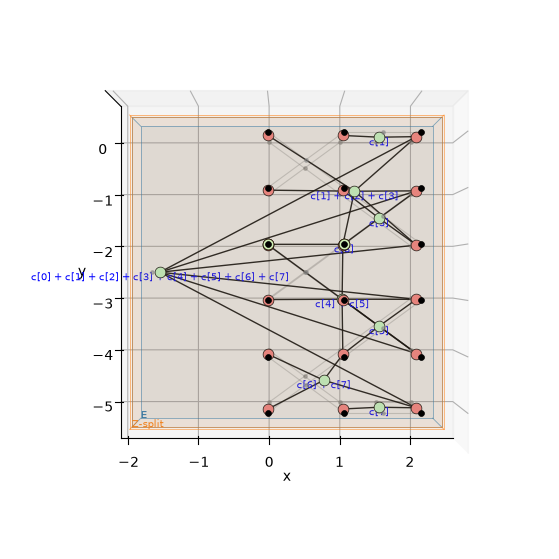

In [4]:
draw_level_3d(split, s1, view='top', figsize=(7, 7))

### Step 2: the outcome moves into the patch

After `'gpf'` on everything there is no separate measurement any more: its outcome `c[8]` has joined the phases of the checks next to the cut (the phases are written modulo the detectors). The diagram is the same map as the circuit for both outcomes of the split, with the outcomes of the encoding set to 0 (in all 512 runs it is the same too, but comparing 512 tensors with 19 legs takes minutes):

the same map as the circuit, for both outcomes of the split: True


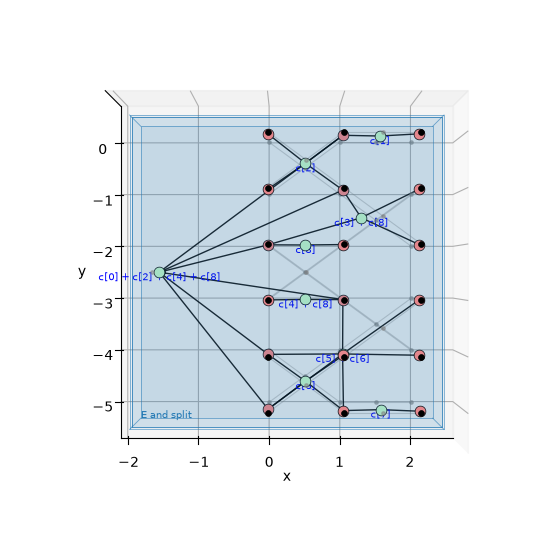

In [5]:
level = split.reduced_level(s2)
encoding = {name: 0 for name in boolean_variables(split_graph) if name != 'c[8]'}
print("the same map as the circuit, for both outcomes of the split:",
      equal_for_all_assignments(split_graph.substitute_variables(encoding), level.graph.substitute_variables(encoding)))
draw_level_3d(split, s2, view='top', figsize=(7, 7))

### Step 3: every outcome phase on a spider of its own

The same diagram with the outcome phases unfused, and from the side: time runs upwards, the encoder's inputs at the bottom, the 18 outputs at the top.

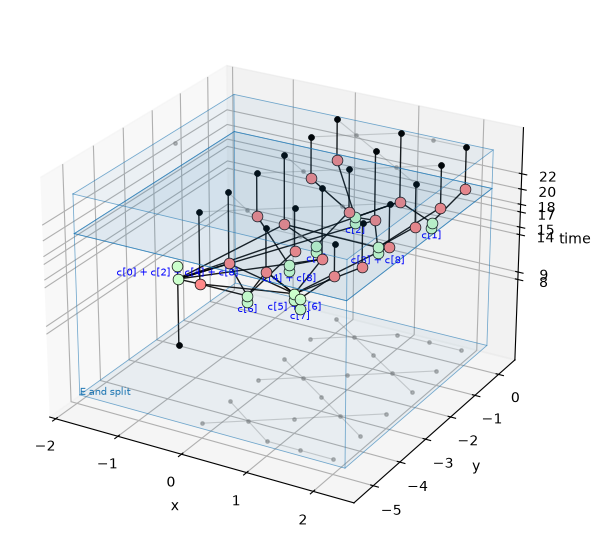

In [6]:
draw_level_3d(split, s3, figsize=(8, 7))

### The logical picture: a Z-copy and two encoders

The tool reads the code after the split as one [[18,1,3]] code: the two halves still share the stabilizer $Z_L \otimes Z_L$ (their logical $Z$, the top rows of each half, qubits 0–2 and 9–11). Kissinger's last diagram reads them as two patches, $E_{3\times3} \otimes E_{3\times3}$. `separated` gives that code from the one the tool reads, keeping the stabilizers within each half with their signs; between the 6×3 code and the two halves the split is a **Z-split**, in every run. Its diagram, reduced, is the green spider with one leg in and two out (the red spiders on its outputs have two legs and no phase: plain wires):

Z_L x Z_L is a stabilizer: True
[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
[[9, 1, 3]] CSS code on qubits 9, 10, 11, 12, 13, 14, 15, 16, 17
deterministic: every run implements Z-split


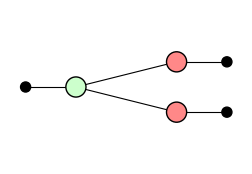

In [7]:
after = split.code_at(1).data()
print("Z_L x Z_L is a stabilizer:", after.contains('ZZZ' + 'I' * 6 + 'ZZZ' + 'I' * 6))
halves = after.separated([list(range(9)), list(range(9, 18))])
for block in halves.blocks():
    print(block.describe().splitlines()[0])
z_split = logical_action(split.block_graph(s1, 1, classical=False), split.code_at(0).data(), halves)
print(z_split.verdict())
zx.draw_matplotlib(z_split.graph, figsize=(3, 2))

## Part 2: the X-merge

Two 3×3 patches side by side, A on columns 0–2 (qubits 0–8) and B on columns 3–5 (qubits 9–17), each encoded from an input of its own (qubits 18 and 19) as in Part 1. B starts at an odd column, so it has the other checkerboard (`parity=1`). The merge measures the X checks of the 3×6 patch that cross the seam between columns 2 and 3: two of them, with outcomes `c[10]` and `c[11]`, Kissinger's $j_1$ and $j_2$. The pictures draw the chip turned by 90°, A above B, as Kissinger stacks his patches.

In [8]:
A = [(r, c) for r in range(3) for c in range(3)]
B = [(r, c) for r in range(3) for c in range(3, 6)]
DATA = {rc: q for q, rc in enumerate(A + B)}
A_IN, B_IN = 18, 19
a_x = [[DATA[(i // 3, i % 3)] for i in np.flatnonzero(row)] for row in surface_code_checks(3)[0]]
b_x = [[DATA[(i // 3, 3 + i % 3)] for i in np.flatnonzero(row)] for row in surface_code_checks(3, parity=1)[0]]
seam = [f for f in ([DATA[(i // 6, i % 6)] for i in np.flatnonzero(row)] for row in surface_code_checks(3, 6)[0])
        if any(q < 9 for q in f) and any(q >= 9 for q in f)]
ANCILLA = {tuple(f): 20 + k for k, f in enumerate(a_x + b_x + seam)}
N, BITS = 20 + len(ANCILLA), 2 + len(ANCILLA)
print("the seam checks:", seam)

# drawn turned by 90 degrees, (row, column) at (row, -column), so that A is above B, as in Kissinger's figure
where = {q: (r, -c) for (r, c), q in DATA.items()}
chip = Topology()
for q, xy in where.items():
    chip.add_node(q, xy)
chip.add_node(A_IN, (-1.5, -1.0))
chip.add_node(B_IN, (-1.5, -4.0))
for f, a in ANCILLA.items():
    chip.add_node(a, tuple(np.mean([where[q] for q in f], axis=0)))
    for q in f:
        chip.add_edge(a, q)

merge = QProgram(N, bits=BITS, topology=chip, initial_states={q: '0' for q in range(N) if q not in (A_IN, B_IN)})
bit = iter(range(BITS))
for name, gates in (
        ('encode A and B', [CNOT(A_IN, DATA[(r, 0)]) for r in range(3)] + [HAD(A_IN), Measurement(A_IN, next(bit))]
                           + [g for f in a_x for a in [ANCILLA[tuple(f)]]
                              for g in [HAD(a)] + [CNOT(a, q) for q in f] + [HAD(a), Measurement(a, next(bit))]]
                           + [CNOT(B_IN, DATA[(r, 3)]) for r in range(3)] + [HAD(B_IN), Measurement(B_IN, next(bit))]
                           + [g for f in b_x for a in [ANCILLA[tuple(f)]]
                              for g in [HAD(a)] + [CNOT(a, q) for q in f] + [HAD(a), Measurement(a, next(bit))]]),
        ('X-merge', [g for f in seam for a in [ANCILLA[tuple(f)]]
                     for g in [HAD(a)] + [CNOT(a, q) for q in f] + [HAD(a), Measurement(a, next(bit))]])):
    c = Circuit(N, bit_amount=BITS)
    for gate in gates:
        c.add_gate(gate)
    merge.add_circuit(c, name=name)
merge_graph = merge.quantum_graph()
for s in range(2):
    print("after stage {}:".format(s), [b.describe().splitlines()[0] for b in merge.code_at(s).blocks()])

the seam checks: [[2, 9, 5, 12], [8, 15]]
after stage 0: ['[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8', '[[9, 1, 3]] CSS code on qubits 9, 10, 11, 12, 13, 14, 15, 16, 17']


after stage 1: ['[[18, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17']


The same three level-ups as for the split.

In [9]:
m1 = merge.group_stages([(0, 0, 'E (x) E', 'encoder', 'gpf'), (1, 1, 'X-merge', None, 'thesis notation')])
m2 = merge.level_up(m1, 0, 1, 'all', rewrite='gpf')
m3 = merge.level_up(m2, 0, 0, 'all', rewrite='unfuse outcomes')
for level in (m1, m2, m3):
    print(merge.describe_level(level), end='\n\n')

Level 2 (2 blocks):
  Block 0 'E (x) E' (encoder) <rewrite: gpf>: [encode A and B]
  Block 1 'X-merge' <rewrite: thesis notation>: [X-merge]

Level 3 (1 blocks):
  Block 0 'all' <rewrite: gpf>: [encode A and B, X-merge]

Level 4 (1 blocks):
  Block 0 'all' <rewrite: unfuse outcomes>: [encode A and B, X-merge]



### Step 1: two encoders, and the two seam checks (Kissinger's first merge diagram)

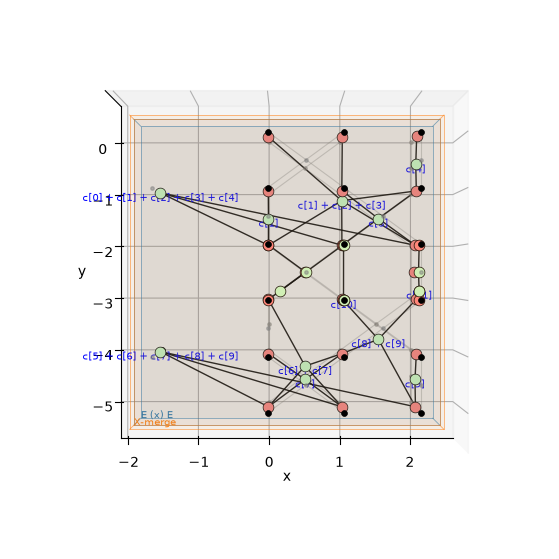

In [10]:
draw_level_3d(merge, m1, view='top', figsize=(7, 7))

### Step 2: kπ on an input

After `'gpf'` on everything, the seam outcomes have gone into the patch, and their parity $k$ = `c[10] + c[11]` sits on the input spider of patch B, together with outcomes of the encoding: Kissinger's "$k\pi$ on the input". A phase on an input acts *before* the map, so no correction after the merge can take it away.

This program has 12 outcomes. Here the diagram is compared with the circuit in every run of the merge's own two outcomes, with the encoding's outcomes set to 0, not in all 4096 runs:

input spider, phase: c[0] + c[2]
input spider, phase: c[1] + c[3] + c[4] + c[5] + c[10] + c[11]


the same map as the circuit, for every outcome of the merge: True


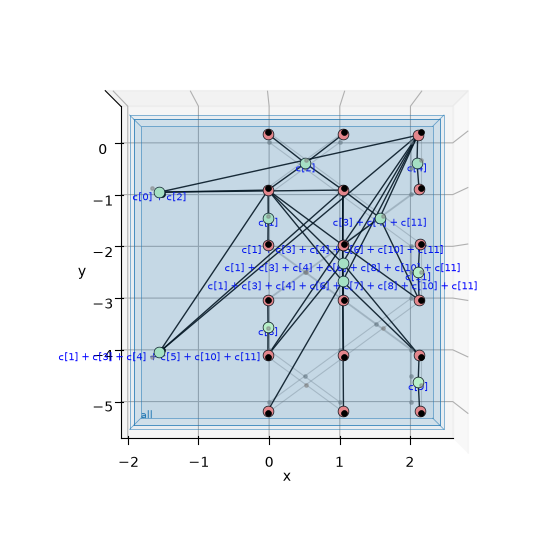

In [11]:
level = merge.reduced_level(m2)
h = phases_modulo(level.graph, level.detectors)
for b in h.inputs():
    (spider,) = list(h.neighbors(b))
    print("input spider, phase:", h.phase(spider))
encoding = {name: 0 for name in boolean_variables(merge_graph) if name not in ('c[10]', 'c[11]')}
print("the same map as the circuit, for every outcome of the merge:",
      equal_for_all_assignments(merge_graph.substitute_variables(encoding), level.graph.substitute_variables(encoding)))
draw_level_3d(merge, m2, view='top', figsize=(7, 7))

### The logical picture: an X-merge

Between the two patches' codes and the merged [[18,1,3]] code, the tool finds a measurement of $XX$: the X-merge onto $XX = +1$ or onto $XX = -1$, selected by the parity $k$. Reduced, its diagram is Kissinger's last one: a green spider with phase $k\pi$ on one input, then a red spider that merges the two.

not deterministic: the operation depends on the outcomes (X-merge, XX = +1 when c[10] + c[11] + c[2] + c[1] + c[3] + c[4] = 0; X-merge, XX = -1 when c[10] + c[11] + c[2] + c[1] + c[3] + c[4] = 1)


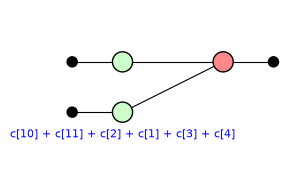

In [12]:
x_merge = logical_action(merge.block_graph(m1, 1, classical=False), merge.code_at(0), merge.code_at(1))
print(x_merge.verdict())
zx.draw_matplotlib(x_merge.graph, figsize=(3, 2))

## Part 3: L. Yeh's recipe on the split ("universal gadget fixing")

1. Unfuse the measurement spiders, separating out the outcome phases $j_1\pi, j_2\pi, \dots$ (Step 3 of Part 1).
2. Rewrite the Z-X normal form into an X-Z normal form: the $j\pi$ phases copy across to the right and become $j\pi$ on the outputs.
3. Read the corrections off the rewrite: applying them makes every $j$ act as $j = 0$.
4. Apply the dagger, and end up with only $j\pi$.

Steps 2 and 3 are two more level-ups of the split: `'x-z gpf'` (the normal form with the colours swapped: a green spider on each output), then `'unfuse outcomes'`. Each outcome phase on an output's green spider is a $Z$ to apply when that parity is 1: the corrections. Kissinger's "error correction" is this step.

Z on qubit 0 when c[2] = 1
Z on qubit 2 when c[1] = 1
Z on qubit 5 when c[0] + c[2] + c[3] + c[4] = 1
Z on qubit 6 when c[0] + c[2] + c[4] + c[8] = 1
Z on qubit 7 when c[0] + c[2] + c[4] = 1
Z on qubit 9 when c[4] + c[8] = 1
Z on qubit 11 when c[5] + c[6] = 1
Z on qubit 13 when c[6] = 1
Z on qubit 17 when c[7] = 1
the same map as the circuit, for both outcomes of the split: True


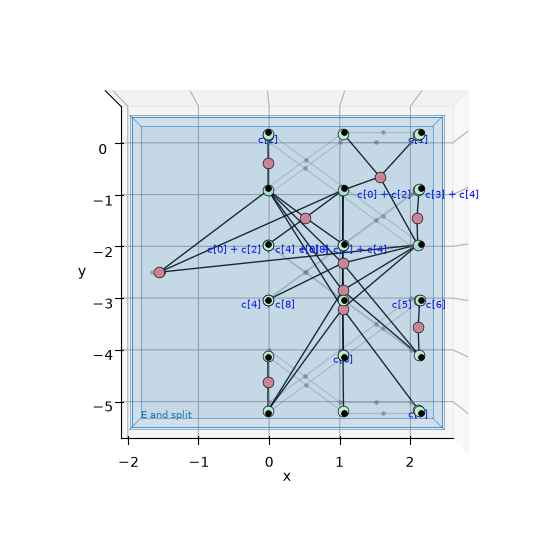

In [13]:
s4 = split.level_up(s3, 0, 0, 'E and split', rewrite='x-z gpf')
s5 = split.level_up(s4, 0, 0, 'E and split', rewrite='unfuse outcomes')
level = split.reduced_level(s4)
h = phases_modulo(level.graph, level.detectors)
for b in h.outputs():
    (spider,) = list(h.neighbors(b))
    if h.phase(spider) != 0:
        print("Z on qubit", get_logical_qubit(h, b), "when", h.phase(spider), "= 1")
level = split.reduced_level(s5)
print("the same map as the circuit, for both outcomes of the split:",
      equal_for_all_assignments(split_graph.substitute_variables(encoding), level.graph.substitute_variables(encoding)))
draw_level_3d(split, s5, view='top', figsize=(7, 7))

The split's own outcome `c[8]` sits on two outputs, qubits 6 and 9, at (2, 0) and (3, 0): one on each side of the cut: Kissinger's $j\pi$ copied onto the outputs. The other phases are outcomes of the encoding, which put random signs on the checks. `find_corrections` reads corrections off the normal forms in the same way, and checks that with them every run is the run with every outcome 0; on these 18 qubits that check compares tensors run by run and can take many minutes, so it is shown on smaller programs in [FindingCorrectionsStepByStep.ipynb](FindingCorrectionsStepByStep.ipynb).

Step 4: the split program, followed by the dagger of the same program in the run where every outcome is 0, rewritten. Everything cancels except a single wire with one phase, `c[0]`: a $Z$ on the logical qubit when the X measurement that put the input into the patch reads 1. The split's own outcome, `c[8]`, is gone: it only set the signs of the new boundary checks, and the Z-split is the same in every run.

4 spiders left


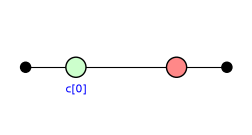

In [14]:
zero = split_graph.substitute_variables({name: 0 for name in boolean_variables(split_graph)})
loop = split_graph.copy()
loop.compose(zero.adjoint())
result = reduce_gpf(loop)
print(result.graph.num_vertices(), "spiders left")
zx.draw_matplotlib(phases_modulo(result.to_graph(), result.constraints), figsize=(3, 1.5))

## How this differs from the figures

* Kissinger's patches are cut and joined along columns; here the split runs between rows and the merge between columns, the same derivations turned by 90°.
* His pictures start from the encoder $E$; here $E$ is a program, an input fanned out onto the logical $X$ and the X checks measured, rewritten into two layers by `'gpf'`. Its checks carry signs, the outcomes of that encoding.
* The "$\equiv$ e.c." step is reading the $Z$ corrections off the X-Z normal form (Part 3); the logical pictures are the tool's logical action between the codes it reads, with the halves after the split read as separate patches (`separated`).
* The rewritten diagrams are compared with the circuit for every outcome of the split or the merge, with the encoding's outcomes 0, not in all runs: comparing every run as a tensor takes minutes to half an hour on these programs.